In [1]:
from google.colab import drive
drive.mount('/content/drive')

import torch
print('GPU var mı:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU adı:', torch.cuda.get_device_name(0))

Mounted at /content/drive
GPU var mı: True
GPU adı: Tesla T4


In [2]:
!mkdir -p /content/data
!tar -xzf /content/drive/MyDrive/FlowerCompetition/flower_data.tar.gz -C /content/data
!cp /content/drive/MyDrive/FlowerCompetition/dataset.py /content/
!ls /content/data

test  train  valid


In [3]:
from dataset import get_dataloaders

DATA_DIR = '/content/data'
BATCH_SIZE = 32

train_loader, valid_loader, test_loader, classes = get_dataloaders(
    DATA_DIR, batch_size=BATCH_SIZE, num_workers=2
)

print('Sınıf sayısı:', len(classes))
print('İlk 10 sınıf:', classes[:10])
print('Train / Valid / Test:', len(train_loader.dataset), len(valid_loader.dataset), len(test_loader.dataset))

Sınıf sayısı: 102
İlk 10 sınıf: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
Train / Valid / Test: 6552 818 819


In [4]:
import torch.nn as nn
from torchvision import models

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ImageNet'te eğitilmiş hazır EfficientNet-B0
weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = models.efficientnet_b0(weights=weights)

print('ESKİ son katman:', model.classifier)

# Son katmanı 1000 sınıftan 102 sınıfa çevir
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, len(classes))

print('YENİ son katman:', model.classifier)

model = model.to(device)

toplam = sum(p.numel() for p in model.parameters())
print(f'Toplam parametre: {toplam:,}  (~{toplam * 4 / 1e6:.1f} MB)')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 219MB/s]


ESKİ son katman: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)
YENİ son katman: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=102, bias=True)
)
Toplam parametre: 4,138,210  (~16.6 MB)


In [5]:
import time

# Kayıp (hata) fonksiyonu
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# Eğitim geçmişi (sonra grafik çizmek için)
history = []


def train_one_epoch(model, loader, optimizer):
    model.train()                      # eğitim modu (dropout açık)
    total_loss, correct, n = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()          # 1) eski düzeltme bilgisini sıfırla
        outputs = model(images)        # 2) tahmin yap
        loss = criterion(outputs, labels)  # 3) ne kadar yanlış? hesapla
        loss.backward()                # 4) hangi ağırlık ne kadar suçlu? hesapla
        optimizer.step()               # 5) ağırlıkları biraz düzelt

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        n += images.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader):
    model.eval()                       # değerlendirme modu (dropout kapalı)
    total_loss, correct, n = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        n += images.size(0)
    return total_loss / n, correct / n

print('Fonksiyonlar hazır.')

Fonksiyonlar hazır.


In [6]:
# Gövdeyi dondur: sadece son katman öğrenecek
for p in model.features.parameters():
    p.requires_grad = False

optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3)
EPOCHS_STAGE1 = 5

for epoch in range(1, EPOCHS_STAGE1 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
    va_loss, va_acc = evaluate(model, valid_loader)
    history.append({'stage': 1, 'epoch': epoch, 'train_loss': tr_loss, 'train_acc': tr_acc,
                    'valid_loss': va_loss, 'valid_acc': va_acc})
    print(f'[Aşama 1] Epoch {epoch}/{EPOCHS_STAGE1} | '
          f'train acc {tr_acc:.3f} | valid acc {va_acc:.3f} | '
          f'valid loss {va_loss:.3f} | {time.time() - t0:.0f} sn')

[Aşama 1] Epoch 1/5 | train acc 0.535 | valid acc 0.778 | valid loss 1.990 | 73 sn
[Aşama 1] Epoch 2/5 | train acc 0.825 | valid acc 0.848 | valid loss 1.581 | 67 sn
[Aşama 1] Epoch 3/5 | train acc 0.861 | valid acc 0.883 | valid loss 1.447 | 67 sn
[Aşama 1] Epoch 4/5 | train acc 0.889 | valid acc 0.902 | valid loss 1.373 | 66 sn
[Aşama 1] Epoch 5/5 | train acc 0.898 | valid acc 0.913 | valid loss 1.325 | 66 sn


In [7]:
# Gövdeyi çöz: artık bütün model öğrenecek
for p in model.parameters():
    p.requires_grad = True

EPOCHS_STAGE2 = 15
LR_STAGE2 = 1e-4
SAVE_PATH = '/content/drive/MyDrive/FlowerCompetition/efficientnet_best.pth'

optimizer = torch.optim.AdamW(model.parameters(), lr=LR_STAGE2, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_STAGE2)

best_acc = 0.0
for epoch in range(1, EPOCHS_STAGE2 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
    va_loss, va_acc = evaluate(model, valid_loader)
    scheduler.step()

    history.append({'stage': 2, 'epoch': epoch, 'train_loss': tr_loss, 'train_acc': tr_acc,
                    'valid_loss': va_loss, 'valid_acc': va_acc})

    note = ''
    if va_acc > best_acc:
        best_acc = va_acc
        torch.save(model.state_dict(), SAVE_PATH)
        note = '  ★ en iyi, kaydedildi'

    print(f'[Aşama 2] Epoch {epoch}/{EPOCHS_STAGE2} | '
          f'train acc {tr_acc:.3f} | valid acc {va_acc:.3f} | '
          f'valid loss {va_loss:.3f} | {time.time() - t0:.0f} sn{note}')

print(f'\nEn iyi valid accuracy: {best_acc:.4f}')

[Aşama 2] Epoch 1/15 | train acc 0.947 | valid acc 0.965 | valid loss 1.083 | 74 sn  ★ en iyi, kaydedildi
[Aşama 2] Epoch 2/15 | train acc 0.974 | valid acc 0.976 | valid loss 1.042 | 74 sn  ★ en iyi, kaydedildi
[Aşama 2] Epoch 3/15 | train acc 0.984 | valid acc 0.979 | valid loss 1.016 | 73 sn  ★ en iyi, kaydedildi
[Aşama 2] Epoch 4/15 | train acc 0.993 | valid acc 0.977 | valid loss 0.998 | 73 sn
[Aşama 2] Epoch 5/15 | train acc 0.993 | valid acc 0.979 | valid loss 0.985 | 74 sn
[Aşama 2] Epoch 6/15 | train acc 0.996 | valid acc 0.983 | valid loss 0.975 | 74 sn  ★ en iyi, kaydedildi
[Aşama 2] Epoch 7/15 | train acc 0.996 | valid acc 0.983 | valid loss 0.962 | 74 sn
[Aşama 2] Epoch 8/15 | train acc 0.998 | valid acc 0.979 | valid loss 0.963 | 74 sn
[Aşama 2] Epoch 9/15 | train acc 0.998 | valid acc 0.985 | valid loss 0.952 | 74 sn  ★ en iyi, kaydedildi
[Aşama 2] Epoch 10/15 | train acc 0.998 | valid acc 0.983 | valid loss 0.953 | 74 sn
[Aşama 2] Epoch 11/15 | train acc 0.999 | valid a

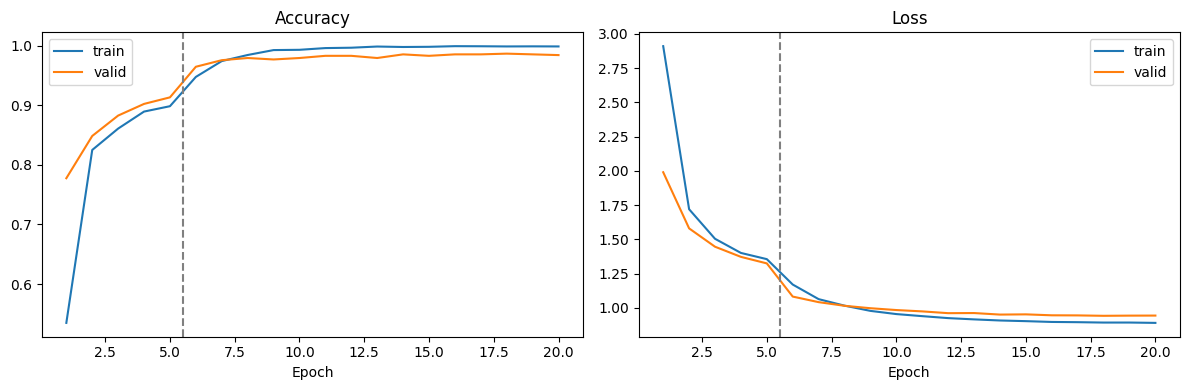

In [8]:
import matplotlib.pyplot as plt

xs = list(range(1, len(history) + 1))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(xs, [h['train_acc'] for h in history], label='train')
ax1.plot(xs, [h['valid_acc'] for h in history], label='valid')
ax1.set_title('Accuracy'); ax1.set_xlabel('Epoch'); ax1.legend()

ax2.plot(xs, [h['train_loss'] for h in history], label='train')
ax2.plot(xs, [h['valid_loss'] for h in history], label='valid')
ax2.set_title('Loss'); ax2.set_xlabel('Epoch'); ax2.legend()

# Aşama 1 ile Aşama 2'nin ayrıldığı yer
for ax in (ax1, ax2):
    ax.axvline(EPOCHS_STAGE1 + 0.5, ls='--', c='gray')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FlowerCompetition/efficientnet_training.png', dpi=120)
plt.show()

In [9]:
model.load_state_dict(torch.load(SAVE_PATH, map_location=device))
te_loss, te_acc = evaluate(model, test_loader)
print(f'Test accuracy: {te_acc:.4f}  ({te_acc*100:.2f}%)')

Test accuracy: 0.9792  (97.92%)


In [10]:
import copy, statistics

# Modelin CPU'ya kopyasını al (GPU'daki modele dokunmuyoruz)
cpu_model = copy.deepcopy(model).cpu().eval()

# Test setinden 100 fotoğraf al, tek tek (batch = 1) ölçeceğiz
samples = [test_loader.dataset[i][0].unsqueeze(0) for i in range(100)]

with torch.no_grad():
    # Isınma: ilk tahminler hep yavaştır, bunları saymıyoruz
    for x in samples[:10]:
        cpu_model(x)

    times = []
    for x in samples:
        t0 = time.perf_counter()
        cpu_model(x)
        times.append((time.perf_counter() - t0) * 1000)   # milisaniye

ms_per_image = statistics.mean(times)
print(f'CPU çekirdek sayısı (Colab): {torch.get_num_threads()}')
print(f'Ortalama: {ms_per_image:.1f} ms/foto | Ortanca: {statistics.median(times):.1f} ms')

CPU çekirdek sayısı (Colab): 1
Ortalama: 48.5 ms/foto | Ortanca: 47.0 ms


In [11]:
import os

size_mb = os.path.getsize(SAVE_PATH) / (1024 * 1024)

acc_score   = te_acc * 100
speed_score = min(100, 50 / ms_per_image * 100)
size_score  = min(100, 35 / size_mb * 100)
final       = 0.60 * acc_score + 0.25 * speed_score + 0.15 * size_score

print(f'Model dosyası: {size_mb:.2f} MB')
print(f'Accuracy puanı: {acc_score:.2f} | Hız puanı: {speed_score:.1f} | Boyut puanı: {size_score:.1f}')
print(f'Tahmini final puan: {final:.2f} / 100')

Model dosyası: 16.07 MB
Accuracy puanı: 97.92 | Hız puanı: 100.0 | Boyut puanı: 100.0
Tahmini final puan: 98.75 / 100


In [12]:
import json

metrics = {
    'model_name': 'EfficientNet-B0 (fine-tuned)',
    'accuracy': round(te_acc, 4),
    'inference_ms_per_image': round(ms_per_image, 2),
    'model_size_mb': round(size_mb, 2),
    'device': 'cpu (Colab, 1 thread)',
    'num_test_images': len(test_loader.dataset),
    'best_valid_accuracy': round(best_acc, 4),
}

results_dir = '/content/drive/MyDrive/FlowerCompetition/results'
os.makedirs(results_dir, exist_ok=True)
with open(f'{results_dir}/efficientnet_b0_metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)

print(json.dumps(metrics, indent=2))

{
  "model_name": "EfficientNet-B0 (fine-tuned)",
  "accuracy": 0.9792,
  "inference_ms_per_image": 48.47,
  "model_size_mb": 16.07,
  "device": "cpu (Colab, 1 thread)",
  "num_test_images": 819,
  "best_valid_accuracy": 0.9866
}
